# ViGoEmotions — Kaggle: neural baselines
Attach hai Dataset riêng tư: code và ba CSV. Bật GPU + Internet.
Chạy từng cell từ trên xuống; nếu lỗi thì dừng. Hướng dẫn: docs/kaggle_guide.md.
Cell đầu chỉ chạy một lần trong session mới. Kết quả lưu trong /kaggle/working.
Đây là một lượt chạy mới; không dùng để resume sweep Colab khác môi trường.


In [1]:
from pathlib import Path
import os, shutil, zipfile

INPUT = Path('/kaggle/input')
ROOT = Path('/kaggle/working/ViGoEmotions')
if ROOT.exists():
    raise FileExistsError(f'{ROOT} đã tồn tại. Không giải nén đè lên kết quả; chạy tiếp cell cần thiết hoặc dùng session mới.')

# Kaggle có thể giữ ZIP hoặc tự giải nén ZIP khi tạo Dataset.
archives = list(INPUT.rglob('vigoemotions_colab.zip'))
code_roots = [p.parent.parent for p in INPUT.rglob('scripts/common.py')]
if len(archives) == 1:
    with zipfile.ZipFile(archives[0]) as archive:
        for item in archive.infolist():
            if not (ROOT / item.filename).resolve().is_relative_to(ROOT.resolve()):
                raise ValueError('Unsafe ZIP path')
        ROOT.mkdir(parents=True)
        archive.extractall(ROOT)
elif not archives and len(code_roots) == 1:
    shutil.copytree(code_roots[0], ROOT)
else:
    raise RuntimeError('Hãy attach đúng một Dataset code chứa vigoemotions_colab.zip hoặc project đã giải nén.')
os.chdir(ROOT)
print('Project:', ROOT)


Project: /kaggle/working/ViGoEmotions


In [2]:
%pip install -q -r requirements-colab.txt
import shutil, subprocess
if shutil.which('java') is None:
    subprocess.run(['apt-get', '-qq', 'update'], check=True)
    subprocess.run(['apt-get', '-qq', 'install', '-y', 'default-jre-headless'], check=True)


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [3]:
import torch, subprocess
assert torch.cuda.is_available(), 'Hãy bật GPU runtime trước khi chạy tiếp.'
print('GPU:', torch.cuda.get_device_name(0))
subprocess.run(['java','-version'], check=True)

GPU: Tesla T4


openjdk version "21.0.12" 2026-07-21
OpenJDK Runtime Environment (build 21.0.12+8-1-24.04-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12+8-1-24.04-Ubuntu, mixed mode, sharing)


CompletedProcess(args=['java', '-version'], returncode=0)

## Nạp dữ liệu
Attach Dataset chứa train.csv, val.csv, test.csv vào Input. Cell dưới copy CSV vào project để các script dùng chung đường dẫn.


In [4]:
from pathlib import Path
import csv, shutil

sources = {}
for name in ('train.csv', 'val.csv', 'test.csv'):
    candidates = list(Path('/kaggle/input').rglob(name))
    if len(candidates) != 1:
        raise RuntimeError(f'Cần đúng một {name} trong Input; tìm thấy {len(candidates)}. Kiểm tra Dataset đã attach.')
    with candidates[0].open(encoding='utf-8-sig', newline='') as handle:
        if next(csv.reader(handle)) != ['id', 'text', 'labels']:
            raise ValueError(f'{name}: schema phải là id,text,labels')
    sources[name] = candidates[0]
(ROOT / 'data').mkdir(exist_ok=True)
for name, source in sources.items():
    shutil.copy2(source, ROOT / 'data' / name)
    print('Đã nạp:', name)


Đã nạp: train.csv
Đã nạp: val.csv
Đã nạp: test.csv


## Ghi log và hiển thị kết quả
Chạy ô định nghĩa helper trước các ô huấn luyện. Log lưu stdout/stderr của kiểm thử, EDA, TF-IDF, BiGRU, PhoBERT và build report. Mỗi file log ghi đè khi chạy lại cùng bước; tải kết quả trước nếu cần giữ lượt cũ. Cell cài môi trường/VnCoreNLP vẫn hiển thị output trực tiếp trong notebook.

In [5]:
import sys, subprocess, json, os
from datetime import datetime, timezone
import pandas as pd
from IPython.display import display

sys.path.insert(0, str(ROOT/'scripts'))

def run_logged(arguments, name):
    """Stream subprocess output to the notebook and persist it, including failures."""
    log_path = ROOT/'reports/logs'/f'{name}.log'
    log_path.parent.mkdir(parents=True, exist_ok=True)
    env = dict(os.environ, PYTHONUNBUFFERED='1')
    with log_path.open('w', encoding='utf-8') as log:
        header = f"Started UTC: {datetime.now(timezone.utc).isoformat()}\nCommand: {arguments!r}\n"
        log.write(header); log.flush()
        print(header, end='', flush=True)
        with subprocess.Popen(arguments, cwd=ROOT, env=env, stdout=subprocess.PIPE,
                              stderr=subprocess.STDOUT, text=True, encoding='utf-8',
                              errors='replace', bufsize=1) as process:
            for line in process.stdout:
                print(line, end='', flush=True)
                log.write(line); log.flush()
            code = process.wait()
        log.write(f'\nExit code: {code}\n')
    print('Log:', log_path)
    if code:
        raise subprocess.CalledProcessError(code, arguments)

def show_training_summary(name):
    run = json.loads((ROOT/'reports'/f'{name}_run.json').read_text())
    history = pd.DataFrame(run['history'])
    history['selected_checkpoint'] = history.epoch.eq(run['best_epoch'])
    history.to_csv(ROOT/'reports/tables'/f'{name}_history.csv', index=False)
    print(f"{name}: GPU={run['device']}; best epoch={run['best_epoch']}; "
          f"training={run['train_seconds']:.2f}s")
    display(pd.DataFrame([run['config'][name]]))
    display(history)


In [6]:
run_logged([sys.executable,'-m','unittest','discover','-s','tests','-v'], 'tests')
run_logged([sys.executable,'scripts/analyze_data.py'], 'eda')
run_logged([sys.executable,'scripts/train_tfidf.py'], 'tfidf_lr')
display(pd.read_csv('reports/tables/tfidf_lr_metrics.csv'))

Started UTC: 2026-11-03T11:11:19.694610+00:00
Command: ['/usr/bin/python3', '-m', 'unittest', 'discover', '-s', 'tests', '-v']
test_detection_including_duplicates (test_ablate_mixed_neutral.MixedNeutralTests.test_detection_including_duplicates) ... ok
test_exact_exclusion_and_neutral_only_preserved (test_ablate_mixed_neutral.MixedNeutralTests.test_exact_exclusion_and_neutral_only_preserved) ... ok
test_existing_output_is_refused (test_ablate_mixed_neutral.MixedNeutralTests.test_existing_output_is_refused) ... usage: ablate_mixed_neutral.py [-h] [--output OUTPUT]
ablate_mixed_neutral.py: error: Output already exists; choose a fresh subdirectory to preserve results
ok
test_independent_training_and_fixed_seed_reproducibility (test_ablate_mixed_neutral.MixedNeutralTests.test_independent_training_and_fixed_seed_reproducibility) ... ok
test_original_csvs_unchanged_and_test_targets_irrelevant (test_ablate_mixed_neutral.MixedNeutralTests.test_original_csvs_unchanged_and_test_targets_irrelevant

,model,split,threshold,macro_f1,micro_f1,hamming_loss,lrap,parameter_count,train_seconds
0,tfidf_lr,val,0.5,0.238825,0.271238,0.060593,0.640745,940626,2.461771


Tăng epoch: BiGRU từ 10 lên 25; PhoBERT từ 4 lên 20. Chạy cell cấu hình sau Tests + EDA + TF-IDF và trước huấn luyện.

In [7]:
import json
from pathlib import Path

config_path = Path(
    "/kaggle/working/ViGoEmotions/configs/midterm.json"
)
config = json.loads(config_path.read_text(encoding="utf-8"))

config["gru"]["epochs"] = 25
config["phobert"]["epochs"] = 20

config_path.write_text(
    json.dumps(config, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("BiGRU:", config["gru"]["epochs"], "epoch")
print("PhoBERT:", config["phobert"]["epochs"], "epoch")

BiGRU: 25 epoch
PhoBERT: 20 epoch


## 1. Recurrent baseline: BiGRU
Embedding 128, hidden 128 mỗi hướng, dropout 0.3, 25 epoch, batch 64. Chọn epoch theo validation Macro-F1 tại ngưỡng 0.5; không early-stop bằng test.

In [8]:
run_logged([sys.executable,'scripts/train_neural.py','--model','gru'], 'gru')
show_training_summary('gru')

Started UTC: 2026-11-03T11:11:47.947319+00:00
Command: ['/usr/bin/python3', 'scripts/train_neural.py', '--model', 'gru']
Device: cuda
{'epoch': 1, 'loss': 0.27273018645180114, 'macro_f1': 0.03555485700722091, 'micro_f1': 0.05021340697966357, 'hamming_loss': 0.06781757556200925, 'lrap': 0.43555806570508115}
{'epoch': 2, 'loss': 0.2065822219206792, 'macro_f1': 0.17834929375776645, 'micro_f1': 0.2425156149041568, 'hamming_loss': 0.06304901222616614, 'lrap': 0.5648334368173931}
{'epoch': 3, 'loss': 0.17905382400956646, 'macro_f1': 0.27129847835997006, 'micro_f1': 0.34738682727802606, 'hamming_loss': 0.060216557312394677, 'lrap': 0.6024996917573717}
{'epoch': 4, 'loss': 0.16171961634071105, 'macro_f1': 0.3152110421763484, 'micro_f1': 0.391425908667288, 'hamming_loss': 0.058531425907998993, 'lrap': 0.619651950683619}
{'epoch': 5, 'loss': 0.14778557262021128, 'macro_f1': 0.3439695478465623, 'micro_f1': 0.4115942028985507, 'hamming_loss': 0.058226668100821055, 'lrap': 0.6299632642860445}
{'epo

,max_vocab,embedding_dim,hidden_dim,dropout,max_length,epochs,batch_size,learning_rate
0,30000,128,128,0.3,128,25,64,0.001


,epoch,loss,macro_f1,micro_f1,hamming_loss,lrap,selected_checkpoint
0,1,0.272730,0.035555,0.050213,0.067818,0.435558,False
1,2,0.206582,0.178349,0.242516,0.063049,0.564833,False
2,3,0.179054,0.271298,0.347387,0.060217,0.602500,False
3,4,0.161720,0.315211,0.391426,0.058531,0.619652,False
4,5,0.147786,0.343970,0.411594,0.058227,0.629963,False
5,6,0.135326,0.358129,0.416127,0.058155,0.631172,False
6,7,0.123360,0.385379,0.440376,0.058639,0.632375,False
7,8,0.112005,0.398560,0.447047,0.059249,0.633132,False
8,9,0.101739,0.397567,0.446911,0.059858,0.630990,False
9,10,0.092713,0.406002,0.452609,0.060360,0.632236,False


## 2. PhoBERT
Checkpoint/revision được khóa trong configs/midterm.json. Dùng VnCoreNLP để word segmentation trước BPE theo model card. Classification head 27 logits, BCEWithLogitsLoss, sigmoid khi suy luận. Lần chạy đầu tải checkpoint và tài nguyên segmenter từ mạng.
Huấn luyện 20 epoch theo cell cấu hình phía trên.

In [9]:
import py_vncorenlp
segmenter_dir = (ROOT/'data/vncorenlp').resolve()
segmenter_dir.mkdir(parents=True,exist_ok=True)
py_vncorenlp.download_model(save_dir=str(segmenter_dir))
run_logged([sys.executable,'scripts/train_neural.py','--model','phobert',
            '--vncorenlp-dir',str(segmenter_dir)], 'phobert')
show_training_summary('phobert')

--2026-11-03 11:13:34--  https://raw.githubusercontent.com/vncorenlp/VnCoreNLP/master/VnCoreNLP-1.2.jar
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 27412703 (26M) [application/octet-stream]
Saving to: ‘VnCoreNLP-1.2.jar’

     0K .......... .......... .......... .......... ..........  0% 33.3M 1s
    50K .......... .......... .......... .......... ..........  0% 34.9M 1s
   100K .......... .......... .......... .......... ..........  0% 34.6M 1s
   150K .......... .......... .......... .......... ..........  0%  218M 1s
   200K .......... .......... .......... .......... ..........  0%  191M 1s
   250K .......... .......... .......... .......... ..........  1% 57.7M 0s
   300K .......... .......... .......... .......... ..........  1%  110M 0s
   350K ..

Started UTC: 2026-11-03T11:13:37.695399+00:00
Command: ['/usr/bin/python3', 'scripts/train_neural.py', '--model', 'phobert', '--vncorenlp-dir', '/kaggle/working/ViGoEmotions/data/vncorenlp']


200 OK
Length: 16048864 (15M) [application/octet-stream]
Saving to: ‘vi-dep.xz’

     0K .......... .......... .......... .......... ..........  0% 27.7M 1s
    50K .......... .......... .......... .......... ..........  0% 32.1M 1s
   100K .......... .......... .......... .......... ..........  0%  147M 0s
   150K .......... .......... .......... .......... ..........  1%  174M 0s
   200K .......... .......... .......... .......... ..........  1% 42.3M 0s
   250K .......... .......... .......... .......... ..........  1%  202M 0s
   300K .......... .......... .......... .......... ..........  2%  143M 0s
   350K .......... .......... .......... .......... ..........  2%  212M 0s
   400K .......... .......... .......... .......... ..........  2%  244M 0s
   450K .......... .......... .......... .......... ..........  3%  237M 0s
   500K .......... .......... .......... .......... ..........  3% 91.8M 0s
   550K .......... .......... .......... .......... ..........  3%  170M 0s
   600K

Device: cuda
2026-11-03 11:13:44 INFO  WordSegmenter:24 - Loading Word Segmentation model
Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at vinai/phobert-base-v2 and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
{'epoch': 1, 'loss': 0.25797234034437305, 'macro_f1': 0.028478376126637884, 'micro_f1': 0.09036289353520788, 'hamming_loss': 0.06785342942167724, 'lrap': 0.5300794708845483}
{'epoch': 2, 'loss': 0.18111556232408257, 'macro_f1': 0.29311264153595706, 'micro_f1': 0.40540540540540543, 'hamming_loss': 0.05758129862679717, 'lrap': 0.6779678976941148}
{'epoch': 3, 'loss': 0.1443934771286958, 'macro_f1': 0.45087114976318815, 'micro_f1': 0.5234899328859061, 'hamming_loss': 0.05345810476497795, 'lrap': 0.7145788536139575}
{'epoch': 4, 'loss': 0

,checkpoint,max_length,epochs,batch_size,learning_rate,weight_decay,revision
0,vinai/phobert-base-v2,256,20,16,0.00002,0.01,86cd7fd4c148980922ac11a2cf5e257f2ba639e1


,epoch,loss,macro_f1,micro_f1,hamming_loss,lrap,selected_checkpoint
0,1,0.257972,0.028478,0.090363,0.067853,0.530079,False
1,2,0.181116,0.293113,0.405405,0.057581,0.677968,False
2,3,0.144393,0.450871,0.523490,0.053458,0.714579,False
3,4,0.121090,0.494762,0.541753,0.051647,0.732646,False
4,5,0.104466,0.563363,0.577848,0.052884,0.738444,False
5,6,0.090873,0.579560,0.587959,0.053494,0.736620,False
6,7,0.079050,0.569748,0.589517,0.054050,0.741395,False
7,8,0.068929,0.592878,0.605438,0.052293,0.747428,False
8,9,0.059532,0.593676,0.605668,0.052382,0.744790,False
9,10,0.051847,0.589184,0.595721,0.052849,0.743473,False


## 3. So sánh, đường học và xuất báo cáo
Bảng chung gồm Macro/Micro-F1, Hamming Loss, LRAP, tham số và thời gian. Biểu đồ lưu train BCE loss và validation Macro-F1 theo epoch; chưa có validation loss. Đường học không tự chứng minh overfitting/hội tụ. Mỗi lượt chọn checkpoint tốt nhất, không mặc định lấy epoch cuối.

Ca lỗi đã được xuất tự động vào `reports/tables/*_error_cases_val.csv`; nhóm vẫn cần đọc và viết diễn giải thủ công. Các bảng trong phần này dùng validation tại ngưỡng 0,5.

Started UTC: 2026-11-03T15:43:45.522413+00:00
Command: ['/usr/bin/python3', 'scripts/build_report.py']
Wrote midterm_report.md/pdf, midterm_slides.md/pdf, model comparison tables
Log: /kaggle/working/ViGoEmotions/reports/logs/build_report.log


,model,status,macro_f1,micro_f1,hamming_loss,lrap,parameter_count,train_seconds
0,TF-IDF + OvR LR,Đã chạy,0.238825,0.271238,0.060593,0.640745,940626,2.461771
1,BiGRU,Đã chạy,0.421976,0.459037,0.062619,0.619133,2128283,87.374654
2,PhoBERT,Đã chạy,0.595957,0.599159,0.054713,0.741002,135019035,16121.591892


,style,n,gru_macro_f1,phobert_macro_f1,delta_macro_f1
0,all,2066,0.421976,0.595957,0.173981
1,short_le_5,343,0.430315,0.582010,0.151696
2,emoji_heavy_ge_2,199,0.350590,0.488690,0.138100
3,teencode,307,0.333346,0.552570,0.219223


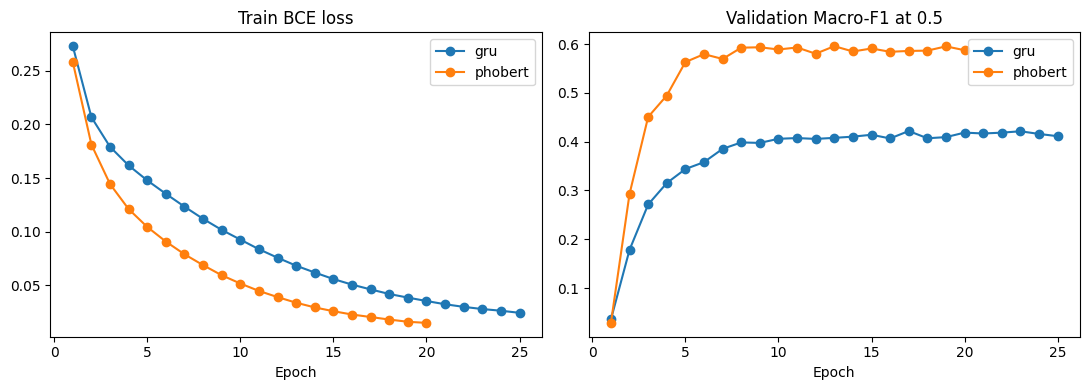

In [10]:
run_logged([sys.executable,'scripts/build_report.py'], 'build_report')
display(pd.read_csv('reports/tables/model_comparison.csv'))
display(pd.read_csv('reports/tables/neural_style_comparison.csv'))

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in ('gru', 'phobert'):
    history = pd.read_csv(f'reports/tables/{name}_history.csv')
    axes[0].plot(history.epoch, history.loss, 'o-', label=name)
    axes[1].plot(history.epoch, history.macro_f1, 'o-', label=name)
for axis, title in zip(axes, ('Train BCE loss', 'Validation Macro-F1 at 0.5')):
    axis.set(title=title, xlabel='Epoch')
    axis.legend()
fig.tight_layout()
fig.savefig('reports/figures/neural_learning_curves.png', dpi=150)
plt.show()

In [11]:
import zipfile
with zipfile.ZipFile('/kaggle/working/vigoemotions_results.zip','w',zipfile.ZIP_DEFLATED) as z:
    for folder in ('reports','splits'):
        for p in Path(folder).rglob('*'):
            if p.is_file():
                z.write(p,str(p))
print('Output cần tải:', '/kaggle/working/vigoemotions_results.zip')


Output cần tải: /kaggle/working/vigoemotions_results.zip


## 4. Tải checkpoint và vocabulary riêng tư
Chạy cả ô tạo ZIP kết quả ở trên và ô dưới. ZIP kết quả chứa log/history/metrics/probabilities/report nhưng không có trọng số. ZIP riêng tư chứa hai checkpoint tốt nhất, vocabulary BiGRU và config/run metadata để khôi phục.

File trọng số lớn nên đợi tải hoàn tất trước khi đóng runtime. Lưu ZIP riêng tư ở máy/Drive riêng; không đưa vào repo công khai. Các file chỉ lưu `state_dict`, không có optimizer state để resume chính xác giữa chừng.

Sau khi nhập kết quả 04 về project local, tạo lại ZIP code với `--include-results`, rồi chạy notebook 05 để tuning learning rate. Tài liệu: [model card PhoBERT](https://huggingface.co/vinai/phobert-base-v2); hướng dẫn project nằm trong `docs/phobert_tuning.md`.

In [12]:
private_paths = [
    Path('data/checkpoints/gru_best.pt'),
    Path('data/checkpoints/phobert_best.pt'),
    Path('data/derived/gru_vocab.json'),
    Path('configs/midterm.json'),
    Path('reports/gru_run.json'),
    Path('reports/phobert_run.json'),
]
for path in private_paths:
    if not path.is_file():
        raise FileNotFoundError(f'Thiếu file cần lưu: {path}')
private_zip = Path('/kaggle/working/vigoemotions_baseline_private.zip')
with zipfile.ZipFile(private_zip, 'w', zipfile.ZIP_DEFLATED) as archive:
    for path in private_paths:
        archive.write(path, str(path))
print('Private ZIP:', private_zip, f'({private_zip.stat().st_size / 1024**2:.1f} MiB)')
print('Output cần tải:', str(private_zip))


Private ZIP: /kaggle/working/vigoemotions_baseline_private.zip (486.3 MiB)
Output cần tải: /kaggle/working/vigoemotions_baseline_private.zip
